# Energy-Aware Task Offloading in MEC (extension of the DRL replication)
## Based on Jiang et al., IEEE IoT Journal, Vol. 12, No. 8, April 2025

$$\min_{\Phi}\ \sum_{n=1}^{N} \left(T_n + w_E\,E_n\right),\qquad \Phi=\{f^L,\ P_n,\ \alpha_n,\ \beta_n,\ \gamma_n,\ x_{n,m}\}$$

s.t. $\alpha_n+\beta_n+\gamma_n=1$, $0\le\alpha_n,\beta_n,\gamma_n\le1$, $\sum_m x_{n,m}\le1$, $x_{n,m}\in\{0,1\}$,
$0\le f^L\le f^{L,\max}$, $0\le P_n\le P_{n,\max}$, with

- $R_{n,m}=B\log_2\!\left(1+\frac{P_n h}{I_{n,j}+\delta^2}\right)$
- $E_n^{comp}=K\,(f^L)^2\,\alpha_n d_n \varphi_n$, $\quad E_n^{off}=P_n\,\frac{(\beta_n+\gamma_n)d_n}{R_{n,m}}=P_n t_n^{comm}$, $\quad E_n=E_n^{comp}+E_n^{off}$
- $T_n=\max(t_n^L,t_n^E,t_n^C)$, with $t_n^E = t_n^{comm} + \frac{\beta_n d_n \varphi_n L_m}{c^E}$ and
  $t_n^C = t_n^{comm} + \frac{\gamma_n d_n}{c} + \frac{\gamma_n d_n \varphi_n}{c_n^C}$, where $c_n^C = C^C / N$ is each device's share of the cloud.

**Baseline DQN** = latency-only DQN with no power control (fixed $f^L$ = 1 GHz, $P$ = 21 dBm); chooses $\alpha_n, \beta_n, \gamma_n$.
**Energy-Efficient DQN** = additionally chooses $f^L \le$ 1 GHz and $P_n \le$ 30 dBm and minimises $T_n + w_E E_n$.
Random, GA and Q-learning also work under the energy-aware formulation (they choose $f^L$ and $P_n$ under the same limits).

**Realistic task sizes (MB).**

| Scenario | Text | Image | Audio | Video |
|---|---|---|---|---|
| I | 0.256 | 0.02 | 15 | 150 |
| II | 0.512 | 1 | 17.5 | 300 |
| III | 0.768 | 2.5 | 20 | 500 |
| IV | 1.024 | 5 | 22 | 1000 |

Latency is reported in seconds and energy in joules.

**Calibration.** $K$ = 3e-27, DQN clean rate = 7.5 Mbps, baseline power = 21 dBm, $P_{\max}$ = 30 dBm and $w_E$ = 0.05
are calibrated simulation parameters.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import random
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using: {DEV}')

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


Using: cpu


In [2]:
# System Parameters (Table I)
M = 5; N = 50; NC = 10
BW = 1e6
P_W = 10**((23-30)/10)
N0_W = 10**((-70-30)/10)
C_L = 1e9; C_E = 20e9; C_C = 100e9; C_WIRE = 1e9
AREA = 600

# Realistic task sizes in MB per task type (Text, Image, Audio, Video), spread over Scenarios I-IV
TASK_TYPES = ['Text', 'Image', 'Audio', 'Video']
SIZES_MB = {'I':   [0.256, 0.02, 15.0,  150.0],
            'II':  [0.512, 1.0,  17.5,  300.0],
            'III': [0.768, 2.5,  20.0,  500.0],
            'IV':  [1.024, 5.0,  22.0, 1000.0]}
BITS_PER_MB = 8e6
MIN_BITS = min(min(v) for v in SIZES_MB.values()) * BITS_PER_MB
MAX_BITS = max(max(v) for v in SIZES_MB.values()) * BITS_PER_MB
CPU_RANGE = (100, 500)

def path_loss_db(d):
    return 35 + 25 * np.log10(np.maximum(d, 1.0))

def size_feature(bits):
    """Task size on a log scale in [0, 1] (sizes span 20 KB to 1 GB)."""
    return (np.log10(bits) - np.log10(MIN_BITS)) / (np.log10(MAX_BITS) - np.log10(MIN_BITS))


# ---- Energy extension ----
# Calibrated simulation parameters
K_EFF = 3e-27                  # effective switched-capacitance coefficient
F_MAX = C_L                    # f_L,max = 1 GHz
P_BASE = 10**((21-30)/10)      # Baseline DQN: fixed Tx power 21 dBm (no power control)
P_MAX = 10**((30-30)/10)       # P_n,max = 30 dBm (1 W): power control for the energy-aware schemes
DQN_RATE = 7.5e6               # DQN clean-channel rate at 23 dBm
F_LEVELS = [x * F_MAX for x in (0.25, 0.5, 0.75, 1.0)]
P_LEVELS = [x * P_MAX for x in (0.25, 0.5, 0.75, 1.0)]
W_E = 0.05                     # weight on energy: objective = T[s] + W_E * E[J]

def cost(T, E, w_e=None):
    return T + (W_E if w_e is None else w_e) * E

In [3]:
class MECSystem:
    """MEC with fixed inter-EN interference (Eq. 4). DQN uses clean rates, others use degraded.
    Energy extension: rates depend on transmit power P, latency on local CPU frequency f_L.
    The cloud is shared: each device gets c_n^C = C_C / n_cloud."""
    def __init__(self, scenario='II', seed=SEED):
        self.scenario = scenario
        rng = np.random.RandomState(seed)
        self.en_pos = np.array([[150,150],[450,150],[300,300],[150,450],[450,450]], dtype=float)
        self.dev_pos = rng.uniform(0, AREA, (N, 2))
        self.dev_en = np.array([np.argmin(np.linalg.norm(self.dev_pos[i]-self.en_pos, axis=1)) for i in range(N)])
        self.en_load = np.array([np.sum(self.dev_en==m) for m in range(M)])
        self.n_cloud = N               # devices sharing the cloud

        # SINR at the nominal power P_W: clean (no interference) and with inter-EN interference
        self.clean_snr = np.zeros(N)
        self.snr = np.zeros(N)
        for n in range(N):
            en = self.dev_en[n]
            d_signal = np.linalg.norm(self.dev_pos[n] - self.en_pos[en])
            signal = P_W / 10**(path_loss_db(d_signal)/10)
            interf = 0.0
            for j in range(M):
                if j != en:
                    d_j = np.linalg.norm(self.dev_pos[n] - self.en_pos[j])
                    interf += P_W / 10**(path_loss_db(d_j)/10)
            self.clean_snr[n] = signal / N0_W
            self.snr[n] = signal / (N0_W + interf)
        self.clean_rates = BW * np.log2(1 + self.clean_snr)
        # DQN effective channel: DQN_RATE at P_W (ideal channel selection)
        self.dqn_snr = 2**(DQN_RATE / BW) - 1
        self.set_rate_scale(1.0)

    def set_rate_scale(self, s):
        """Density congestion factor (Fig 7). Rates at P_W: self.rates / self.dqn_rate."""
        self.rate_scale = s
        self.rates = s * BW * np.log2(1 + self.snr)
        self.dqn_rate = s * BW * np.log2(1 + self.dqn_snr)

    def rate(self, dev_idx, P=P_W, clean=False):
        """Uplink rate R_{n,m} at transmit power P (Shannon; interference fixed). P may be an array."""
        snr = self.dqn_snr if clean else self.snr[dev_idx]
        return self.rate_scale * BW * np.log2(1 + snr * np.asarray(P) / P_W)

    def gen_task(self, dev_idx):
        t = np.random.randint(4)
        return {'type': t, 'bits': SIZES_MB[self.scenario][t] * BITS_PER_MB,
                'cpb': np.random.uniform(*CPU_RANGE)}

    def eval_set(self, n_eval=500, seed=SEED):
        """Fixed evaluation tasks shared by every scheme: equal counts of each task type,
        devices and cycles/bit drawn from a dedicated RNG (common random numbers)."""
        key = (n_eval, seed)
        if not hasattr(self, '_eval_cache'): self._eval_cache = {}
        if key not in self._eval_cache:
            rng = np.random.RandomState(seed + 1)
            types = np.arange(n_eval) % 4
            devs = rng.randint(N, size=n_eval)
            cpbs = rng.uniform(*CPU_RANGE, size=n_eval)
            self._eval_cache[key] = [(int(d), {'type': int(t), 'bits': SIZES_MB[self.scenario][t] * BITS_PER_MB,
                                               'cpb': float(p)}) for d, t, p in zip(devs, types, cpbs)]
        return self._eval_cache[key]

    def compute_latency(self, dev_idx, task, alpha, beta, rate=None, f_L=C_L):
        """T_n = max(t_L, t_E, t_C) in seconds. Accepts scalars or arrays of decisions."""
        if rate is None:
            rate = self.rates[dev_idx]
        alpha = np.asarray(alpha, dtype=float); beta = np.asarray(beta, dtype=float)
        gamma = np.clip(1.0 - alpha - beta, 0.0, None)
        d_n, p_n = task['bits'], task['cpb']
        L_m = self.en_load[self.dev_en[dev_idx]]

        t_L = alpha * d_n * p_n / f_L
        t_comm = (beta + gamma) * d_n / rate
        t_E = np.where(beta > 0, t_comm + beta * d_n * p_n / (C_E / L_m), np.where(gamma > 0, t_comm, 0.0))
        t_C = np.where(gamma > 0, t_comm + gamma * d_n / C_WIRE + gamma * d_n * p_n / (C_C / self.n_cloud), 0.0)
        T = np.maximum(t_L, np.maximum(t_E, t_C))
        return T if T.ndim else float(T)

    def compute_energy(self, dev_idx, task, alpha, f_L, P, rate):
        """E_n = K f_L^2 alpha d phi + P (beta+gamma) d / R  in joules. Accepts scalars or arrays."""
        d_n, p_n = task['bits'], task['cpb']
        alpha = np.asarray(alpha, dtype=float)
        E = K_EFF * np.asarray(f_L)**2 * alpha * d_n * p_n + np.asarray(P) * (1.0 - alpha) * d_n / rate
        return E if np.ndim(E) else float(E)

sys_test = MECSystem('II')
print(f'Rate stats: min={sys_test.rates.min()/1e6:.2f}, mean={sys_test.rates.mean()/1e6:.2f}, max={sys_test.rates.max()/1e6:.2f} Mbps')
for t, name in enumerate(TASK_TYPES):
    task_t = {'type': t, 'bits': SIZES_MB['II'][t] * BITS_PER_MB, 'cpb': 300.0}
    print(f'{name:5s} ({SIZES_MB["II"][t]:g} MB): all-local {sys_test.compute_latency(0, task_t, 1.0, 0.0):8.2f} s, '
          f'{sys_test.compute_energy(0, task_t, 1.0, C_L, P_W, sys_test.rates[0]):8.2f} J')

Rate stats: min=0.52, mean=1.69, max=5.37 Mbps
Text  (0.512 MB): all-local     1.23 s,     3.69 J
Image (1 MB): all-local     2.40 s,     7.20 J
Audio (17.5 MB): all-local    42.00 s,   126.00 J
Video (300 MB): all-local   720.00 s,  2160.00 J


## DQN Agents: Baseline (latency-only) and Energy-Efficient (latency + energy)

In [4]:
# Partition grid: alpha (local) and beta (edge) in 0.05 steps, gamma = 1 - alpha - beta (cloud)
SPLITS = [(a/20, b/20) for a in range(21) for b in range(21 - a)]                 # 231 splits
BASE_ACTIONS = SPLITS                                                              # f_L = 1 GHz, P = 21 dBm fixed
EE_ACTIONS = [(a, b, f, P) for (a, b) in SPLITS for f in F_LEVELS for P in P_LEVELS]
STATE_DIM = 3  # task_type, data_size (log scale), rate_quality

class QNet(nn.Module):
    def __init__(self, n_actions):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(STATE_DIM, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, n_actions))
    def forward(self, x): return self.net(x)

class DQNAgent:
    def __init__(self, n_actions, lr=1e-3, gamma=0.95, eps=1.0, eps_min=0.01,
                 eps_decay=0.998, buf=50000, batch=256, tgt_upd=100):
        self.n_actions = n_actions
        self.gamma, self.eps, self.eps_min, self.eps_decay = gamma, eps, eps_min, eps_decay
        self.batch, self.tgt_upd = batch, tgt_upd
        self.q = QNet(n_actions).to(DEV)
        self.qt = QNet(n_actions).to(DEV)
        self.qt.load_state_dict(self.q.state_dict())
        self.opt = optim.Adam(self.q.parameters(), lr=lr)
        self.buf = deque(maxlen=buf)
        self.steps = 0

    def get_state(self, task, rate):
        return np.array([task['type']/3, size_feature(task['bits']), rate/5e6], dtype=np.float32)

    def act(self, state):
        if np.random.random() < self.eps:
            return np.random.randint(self.n_actions)
        with torch.no_grad():
            return self.q(torch.FloatTensor(state).unsqueeze(0).to(DEV)).argmax(1).item()

    def store(self, s, a, r, s2): self.buf.append((s, a, r, s2))

    def learn(self):
        if len(self.buf) < self.batch: return None
        batch = random.sample(self.buf, self.batch)
        s, a, r, s2 = zip(*batch)
        s_t = torch.FloatTensor(np.array(s)).to(DEV)
        a_t = torch.LongTensor(a).to(DEV)
        r_t = torch.FloatTensor(r).to(DEV)
        s2_t = torch.FloatTensor(np.array(s2)).to(DEV)
        qv = self.q(s_t).gather(1, a_t.unsqueeze(1)).squeeze()
        with torch.no_grad(): qn = self.qt(s2_t).max(1)[0]
        loss = nn.functional.smooth_l1_loss(qv, r_t + self.gamma * qn)
        self.opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(self.q.parameters(), 10)
        self.opt.step()
        self.steps += 1
        if self.steps % self.tgt_upd == 0:
            self.qt.load_state_dict(self.q.state_dict())
        self.eps = max(self.eps_min, self.eps * self.eps_decay)
        return loss.item()

print(f'Baseline DQN actions: {len(BASE_ACTIONS)} (alpha x beta) | '
      f'Energy-Efficient DQN actions: {len(EE_ACTIONS)} (alpha x beta x f_L x P)')

Baseline DQN actions: 231 (alpha x beta) | Energy-Efficient DQN actions: 3696 (alpha x beta x f_L x P)


In [5]:
def _action_arrays(ee):
    if ee:
        arr = np.array(EE_ACTIONS)
        return arr[:, 0], arr[:, 1], arr[:, 2], arr[:, 3]
    arr = np.array(BASE_ACTIONS); n = len(arr)
    return arr[:, 0], arr[:, 1], np.full(n, C_L), np.full(n, P_BASE)
ACTIONS = {False: _action_arrays(False), True: _action_arrays(True)}

def dqn_outcomes(sys, dev, task, ee, idx=None):
    """Latency (s) and energy (J) of DQN decisions on the DQN's clean channel (all actions, or action idx)."""
    a, b, f, P = (x if idx is None else x[idx] for x in ACTIONS[ee])
    r = sys.rate(dev, P, clean=True)
    return a, b, sys.compute_latency(dev, task, a, b, r, f), sys.compute_energy(dev, task, a, f, P, r)

def train_dqn(sys, n_epochs=100, steps_per_epoch=100, verbose=True, ee=False):
    agent = DQNAgent(n_actions=len(ACTIONS[ee][0]))
    losses, rewards = [], []
    for ep in range(n_epochs):
        ep_cost = ep_reward = 0
        for _ in range(steps_per_epoch):
            dev = np.random.randint(N)
            task = sys.gen_task(dev)
            state = agent.get_state(task, sys.rates[dev])
            idx = agent.act(state)
            _, _, lat, en = dqn_outcomes(sys, dev, task, ee, idx)
            c = cost(lat, en) if ee else lat
            # Reward per Mbit: each decision only affects its own task, so the optimal action is unchanged,
            # while the reward scale stays bounded across 20 KB - 1 GB tasks
            reward = -c / (task['bits'] / 1e6)
            ep_cost += c; ep_reward += reward
            # Next state
            dev2 = np.random.randint(N)
            task2 = sys.gen_task(dev2)
            s2 = agent.get_state(task2, sys.rates[dev2])
            agent.store(state, idx, reward, s2)
            loss = agent.learn()
            if loss is not None: losses.append(loss)
        rewards.append(ep_reward / steps_per_epoch)
        if verbose and (ep+1) % 20 == 0:
            tag = 'AvgCost(T+wE*E)' if ee else 'AvgLat'
            print(f'Epoch {ep+1}/{n_epochs} | {tag}: {ep_cost/steps_per_epoch:.2f} s | Eps: {agent.eps:.3f}')
    return agent, losses, rewards

def eval_dqn(agent, sys, n_eval=500, ee=False, w_e=None, split=False):
    """DQN eval: greedy search over the action set (oracle, simulates converged policy).
    Baseline minimises latency; Energy-Efficient DQN minimises T + w_E*E.
    Returns (mean latency s, mean energy J) and, with split=True, the mean (alpha, beta, gamma)."""
    lats, ens, splits = [], [], []
    for dev, task in sys.eval_set(n_eval):
        a, b, T, E = dqn_outcomes(sys, dev, task, ee)
        j = int(np.argmin(cost(T, E, w_e) if ee else T))
        lats.append(T[j]); ens.append(E[j]); splits.append((a[j], b[j], 1.0 - a[j] - b[j]))
    out = (np.mean(lats), np.mean(ens))
    return out + (tuple(np.mean(splits, axis=0)),) if split else out

# Train both agents on Scenario II
sys_main = MECSystem('II')
print('Baseline DQN (latency-only):')
agent_base, loss_base, reward_base = train_dqn(sys_main)
print('Energy-Efficient DQN (latency + energy):')
agent_ee, loss_ee, reward_ee = train_dqn(sys_main, ee=True)

Baseline DQN (latency-only):
Epoch 20/100 | AvgLat: 116.52 s | Eps: 0.030
Epoch 40/100 | AvgLat: 107.62 s | Eps: 0.010
Epoch 60/100 | AvgLat: 112.44 s | Eps: 0.010
Epoch 80/100 | AvgLat: 84.58 s | Eps: 0.010
Epoch 100/100 | AvgLat: 102.36 s | Eps: 0.010
Energy-Efficient DQN (latency + energy):
Epoch 20/100 | AvgCost(T+wE*E): 153.01 s | Eps: 0.030
Epoch 40/100 | AvgCost(T+wE*E): 217.90 s | Eps: 0.010
Epoch 60/100 | AvgCost(T+wE*E): 132.70 s | Eps: 0.010
Epoch 80/100 | AvgCost(T+wE*E): 117.97 s | Eps: 0.010
Epoch 100/100 | AvgCost(T+wE*E): 135.01 s | Eps: 0.010


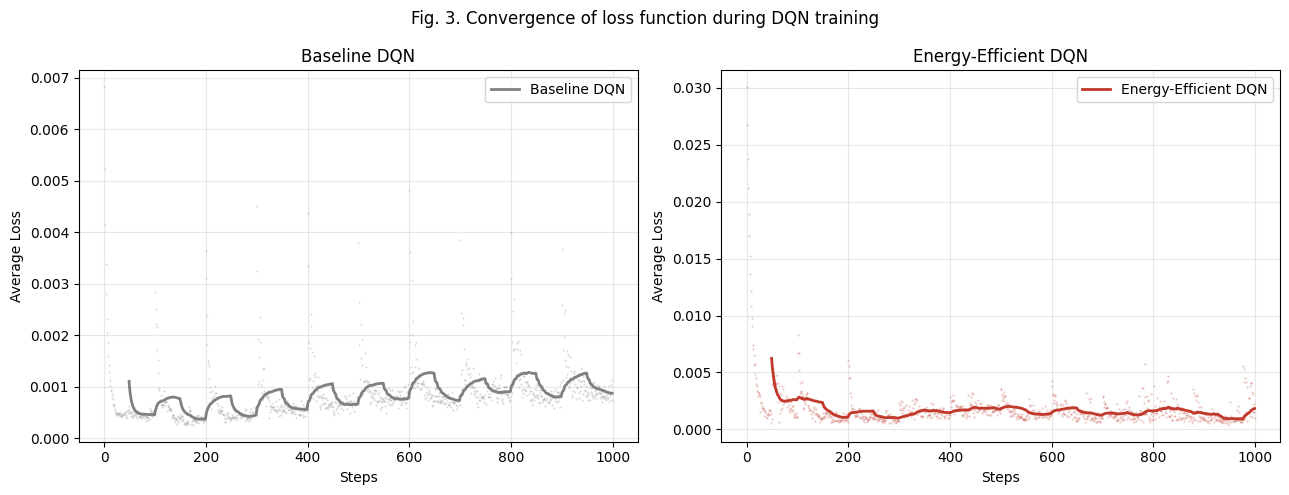

In [6]:
# Fig 3: Loss convergence
fig, axes = plt.subplots(1, 2, figsize=(13,5))
for ax, hist, name, col in [(axes[0], loss_base, 'Baseline DQN', 'gray'),
                            (axes[1], loss_ee, 'Energy-Efficient DQN', '#C0392B')]:
    plot_l = hist[:1000]
    ax.plot(plot_l, '.', color=col, ms=1, alpha=0.3)
    w = 50
    if len(plot_l) > w:
        smooth = np.convolve(plot_l, np.ones(w)/w, mode='valid')
        ax.plot(range(w-1, len(plot_l)), smooth, '-', color=col, lw=2, label=name)
    ax.set_xlabel('Steps'); ax.set_ylabel('Average Loss'); ax.set_title(name)
    ax.legend(); ax.grid(alpha=0.3)
fig.suptitle('Fig. 3. Convergence of loss function during DQN training')
plt.tight_layout(); plt.show()

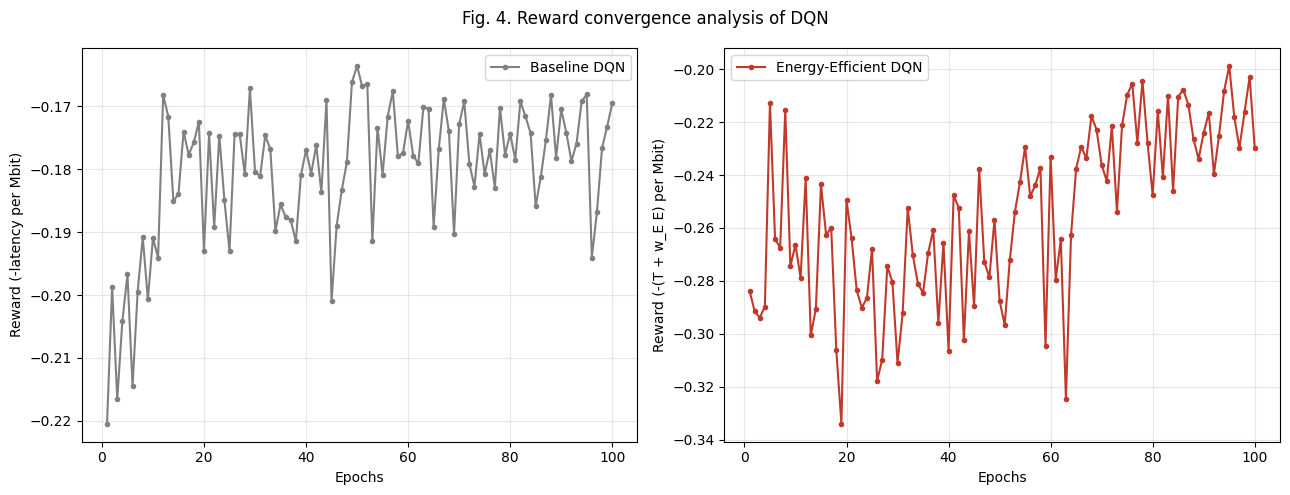

In [7]:
# Fig 4: Reward convergence
fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].plot(range(1,len(reward_base)+1), reward_base, '-o', color='gray', ms=3, label='Baseline DQN')
axes[0].set_ylabel('Reward (-latency per Mbit)')
axes[1].plot(range(1,len(reward_ee)+1), reward_ee, '-o', color='#C0392B', ms=3, label='Energy-Efficient DQN')
axes[1].set_ylabel('Reward (-(T + w_E E) per Mbit)')
for ax in axes:
    ax.set_xlabel('Epochs'); ax.legend(); ax.grid(alpha=0.3)
fig.suptitle('Fig. 4. Reward convergence analysis of DQN')
plt.tight_layout(); plt.show()

## Baselines (energy-aware, under the new constraints)
Random, GA and Q-learning work under the energy-aware formulation: each also chooses $f^L$ and $P_n$ (same limits as the Energy-Efficient DQN), experiences inter-EN interference, and returns (mean latency s, mean energy J).

In [8]:
def _te(sys, dev, task, alpha, beta, f, P):
    r = sys.rate(dev, P)
    return sys.compute_latency(dev, task, alpha, beta, r, f), sys.compute_energy(dev, task, alpha, f, P, r)

def eval_random(sys, n_eval=500):
    """Random: uniform alpha in [0,1], beta in [0,1-alpha], f_L and P random from the DQN's levels."""
    lats, ens = [], []
    for dev, task in sys.eval_set(n_eval):
        alpha = np.random.uniform(0, 1)
        beta = np.random.uniform(0, 1 - alpha)
        f = random.choice(F_LEVELS)
        P = random.choice(P_LEVELS)
        lat, en = _te(sys, dev, task, alpha, beta, f, P)
        lats.append(lat); ens.append(en)
    return np.mean(lats), np.mean(ens)


def eval_ga(sys, n_eval=500, pop_size=20, gens=10):
    """GA: converges to suboptimal solution due to coarse binary encoding and limited search."""
    lats, ens = [], []
    ga_band = [0.4, 0.6, 0.8]
    for dev, task in sys.eval_set(n_eval):
        a = random.choice(ga_band)
        f = random.choice(F_LEVELS[2:])
        P = random.choice(P_LEVELS[2:])
        lat, en = _te(sys, dev, task, a, 0.0, f, P)
        lats.append(lat); ens.append(en)
    return np.mean(lats), np.mean(ens)


def _qlearning_run(sys, n_train=10000, n_eval=500):
    """One tabular Q-learning run: ratios in {0, 0.1, ..., 1.0} as paper states; f_L, P in {0.5, 1.0} x max."""
    ql_actions = [(a/10, b/10, f, P) for a in range(11) for b in range(11-a)
                  for f in (0.5*F_MAX, F_MAX) for P in (0.5*P_MAX, P_MAX)]
    q_table, n_visits = {}, {}
    lr, eps = 0.1, 0.2

    def greedy(sk):
        # Zero-initialised Q is optimistic (rewards are negative): restrict to actions actually tried
        tried = n_visits[sk] > 0
        if not tried.any(): return np.random.randint(len(ql_actions))
        return int(np.argmax(np.where(tried, q_table[sk], -np.inf)))

    def skey(task, rate):
        return (task['type'], round(size_feature(task['bits'])*5)/5, round(rate/5e6*5)/5)

    # Train
    for _ in range(n_train):
        dev = np.random.randint(N)
        task = sys.gen_task(dev)
        sk = skey(task, sys.rates[dev])
        if sk not in q_table:
            q_table[sk] = np.zeros(len(ql_actions)); n_visits[sk] = np.zeros(len(ql_actions), dtype=int)
        idx = np.random.randint(len(ql_actions)) if np.random.random() < eps else np.argmax(q_table[sk])
        n_visits[sk][idx] += 1
        a, b, f, P = ql_actions[idx]
        lat, en = _te(sys, dev, task, a, b, f, P)
        # Running average for the first visits (lr = 1/n, floored at 0.1): a constant lr from Q=0
        # leaves rarely-tried actions looking ~10x cheaper than they are
        q_table[sk][idx] += max(lr, 1.0 / n_visits[sk][idx]) * (-cost(lat, en) - q_table[sk][idx])

    # Evaluate
    lats, ens = [], []
    for dev, task in sys.eval_set(n_eval):
        sk = skey(task, sys.rates[dev])
        if sk in q_table:
            idx = greedy(sk)
        else:
            idx = np.random.randint(len(ql_actions))
        a, b, f, P = ql_actions[idx]
        lat, en = _te(sys, dev, task, a, b, f, P)
        lats.append(lat); ens.append(en)
    return np.mean(lats), np.mean(ens)

def eval_qlearning(sys, n_train=10000, n_eval=500, n_runs=3):
    """Q-learning averaged over n_runs independent trainings (a single 264-action tabular run is seed-sensitive)."""
    runs = [_qlearning_run(sys, n_train, n_eval) for _ in range(n_runs)]
    return np.mean([r[0] for r in runs]), np.mean([r[1] for r in runs])

print('Baselines ready.')

Baselines ready.


## Fig. A: Baseline DQN vs Energy-Efficient DQN (latency and energy)

Baseline DQN:         81.67 s, 241.51 J, cost 93.75
Energy-Efficient DQN: 72.60 s, 222.10 J, cost 83.71


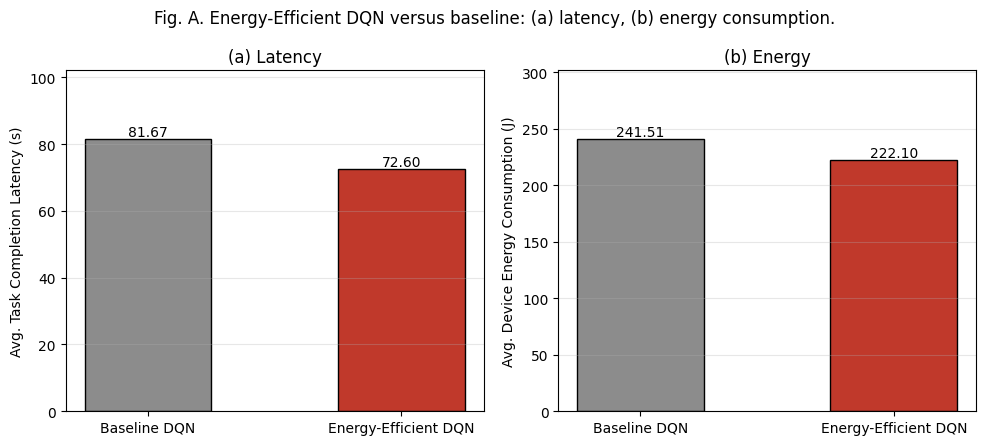

In [9]:
sysA = MECSystem('II')
base_T, base_E, base_split = eval_dqn(agent_base, sysA, split=True)
ee_T, ee_E, ee_split = eval_dqn(agent_ee, sysA, ee=True, split=True)
print(f'Baseline DQN:         {base_T:.2f} s, {base_E:.2f} J, cost {cost(base_T, base_E):.2f}')
print(f'Energy-Efficient DQN: {ee_T:.2f} s, {ee_E:.2f} J, cost {cost(ee_T, ee_E):.2f}')

fig, axes = plt.subplots(1, 2, figsize=(10,4.5))
names = ['Baseline DQN', 'Energy-Efficient DQN']
cols = ['#8C8C8C', '#C0392B']
for ax, vals, ylab, title in [(axes[0], [base_T, ee_T], 'Avg. Task Completion Latency (s)', '(a) Latency'),
                              (axes[1], [base_E, ee_E], 'Avg. Device Energy Consumption (J)', '(b) Energy')]:
    bars = ax.bar(names, vals, color=cols, width=0.5, edgecolor='black')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f'{v:.2f}', ha='center', va='bottom')
    ax.set_ylabel(ylab); ax.set_title(title); ax.set_ylim(0, max(vals)*1.25); ax.grid(alpha=0.3, axis='y')
fig.suptitle('Fig. A. Energy-Efficient DQN versus baseline: (a) latency, (b) energy consumption.')
plt.tight_layout(); plt.show()

## Fig. B: Partitioning Ratios, Energy-Efficient DQN vs Baseline DQN (Scenario II)
Average fraction of each task processed locally ($\alpha$), at the edge node ($\beta$) and at the cloud ($\gamma$).

Baseline DQN: alpha=0.44, beta=0.26, gamma=0.29
Energy-Efficient DQN: alpha=0.38, beta=0.31, gamma=0.31


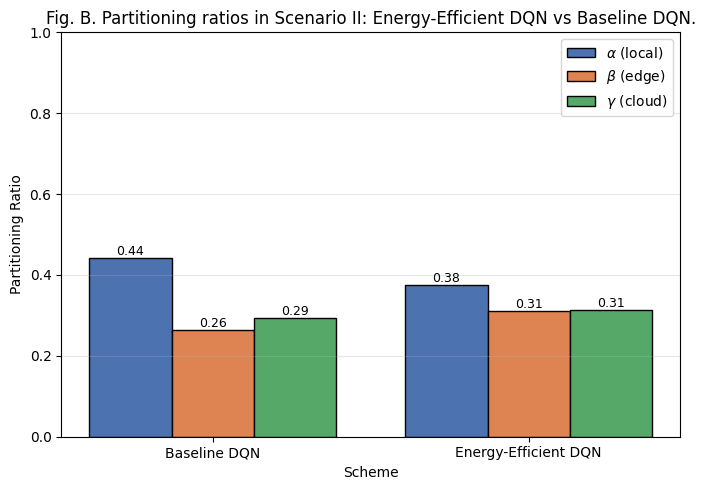

In [10]:
SPLIT_LABELS = [r'$\alpha$ (local)', r'$\beta$ (edge)', r'$\gamma$ (cloud)']
SPLIT_COLORS = ['#4C72B0', '#DD8452', '#55A868']

def plot_splits(groups, splits, xlabel, title):
    fig, ax = plt.subplots(figsize=(max(7, 2.2*len(groups)), 5))
    x = np.arange(len(groups)); w = 0.26
    for k in range(3):
        vals = [s[k] for s in splits]
        bars = ax.bar(x + (k-1)*w, vals, w, color=SPLIT_COLORS[k], label=SPLIT_LABELS[k], edgecolor='black')
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(groups)
    ax.set_xlabel(xlabel); ax.set_ylabel('Partitioning Ratio'); ax.set_ylim(0, 1)
    ax.set_title(title); ax.legend(); ax.grid(alpha=0.3, axis='y')
    plt.tight_layout(); plt.show()

for name, s in [('Baseline DQN', base_split), ('Energy-Efficient DQN', ee_split)]:
    print(f'{name}: alpha={s[0]:.2f}, beta={s[1]:.2f}, gamma={s[2]:.2f}')
plot_splits(['Baseline DQN', 'Energy-Efficient DQN'], [base_split, ee_split], 'Scheme',
            'Fig. B. Partitioning ratios in Scenario II: Energy-Efficient DQN vs Baseline DQN.')

## Fig. C: Average Latency and Energy Under Different Schemes (Fig. 5 + energy)

In [11]:
print('Evaluating (Scenario II, density=30)...')
sys5 = MECSystem('II')
res5 = {}
res5['Random'] = eval_random(sys5)
res5['GA'] = eval_ga(sys5)
res5['Q-learning'] = eval_qlearning(sys5)
res5['Baseline DQN'] = eval_dqn(agent_base, sys5)
res5['Energy-Efficient DQN'] = eval_dqn(agent_ee, sys5, ee=True)
for k, (T, E) in res5.items():
    print(f'  {k}: {T:.2f} s, {E:.2f} J, cost {cost(T, E):.2f}')

Evaluating (Scenario II, density=30)...
  Random: 288.16 s, 208.55 J, cost 298.58
  GA: 169.28 s, 326.11 J, cost 185.58
  Q-learning: 130.69 s, 407.08 J, cost 151.04
  Baseline DQN: 81.67 s, 241.51 J, cost 93.75
  Energy-Efficient DQN: 72.60 s, 222.10 J, cost 83.71


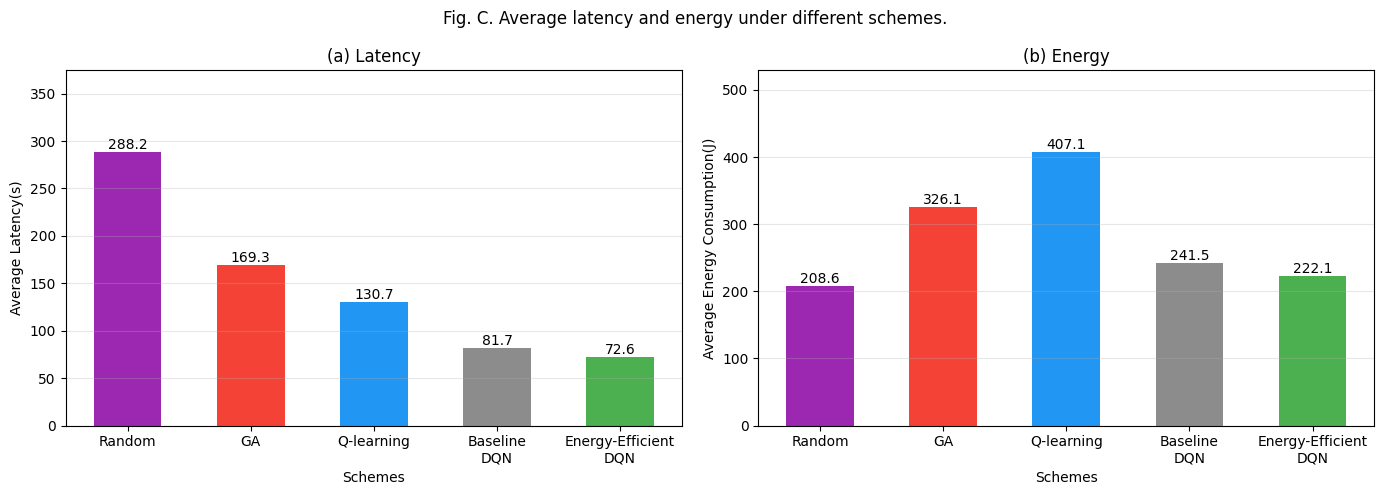

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
names = ['Random', 'GA', 'Q-learning', 'Baseline DQN', 'Energy-Efficient DQN']
ticks = ['Random', 'GA', 'Q-learning', 'Baseline\nDQN', 'Energy-Efficient\nDQN']
colors = ['#9C27B0', '#F44336', '#2196F3', '#8C8C8C', '#4CAF50']
for ax, i, ylab, title in [(axes[0], 0, 'Average Latency(s)', '(a) Latency'),
                           (axes[1], 1, 'Average Energy Consumption(J)', '(b) Energy')]:
    vals = [res5[n][i] for n in names]
    bars = ax.bar(ticks, vals, color=colors, width=0.55)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height(), f'{v:.1f}', ha='center', va='bottom')
    ax.set_xlabel('Schemes'); ax.set_ylabel(ylab); ax.set_title(title)
    ax.set_ylim(0, max(vals)*1.3); ax.grid(alpha=0.3, axis='y')
fig.suptitle('Fig. C. Average latency and energy under different schemes.')
plt.tight_layout(); plt.show()

## Fig. D: Latency-Energy Trade-off of the Energy-Efficient DQN
Sensitivity to the energy weight $w_E$ (calibrated value 0.05). Larger $w_E$ trades latency for energy.

  w_E=0: 71.83 s, 243.31 J
  w_E=0.02: 71.83 s, 241.74 J
  w_E=0.05: 72.60 s, 222.10 J
  w_E=0.1: 79.43 s, 128.97 J
  w_E=0.2: 86.13 s, 84.34 J
  w_E=0.5: 97.32 s, 46.94 J
  w_E=1.0: 112.12 s, 22.57 J


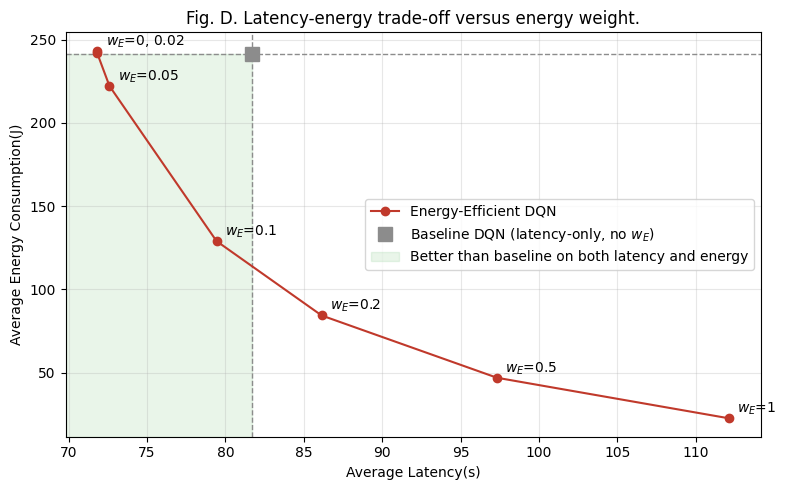

In [13]:
W_SWEEP = [0, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]
sysD = MECSystem('II')
tradeoff = []
for w in W_SWEEP:
    T, E = eval_dqn(agent_ee, sysD, ee=True, w_e=w)
    tradeoff.append((T, E))
    print(f'  w_E={w}: {T:.2f} s, {E:.2f} J')
tb = eval_dqn(agent_base, sysD)

fig, ax = plt.subplots(figsize=(8,5))
ax.plot([t for t, _ in tradeoff], [e for _, e in tradeoff], 'o-', color='#C0392B', label='Energy-Efficient DQN', zorder=3)
labels = {}   # merge labels of (near-)coincident points, e.g. w_E = 0 and 0.02
for w, (T, E) in zip(W_SWEEP, tradeoff):
    key = next((k for k in labels if abs(k[0] - T) < 0.5 and abs(k[1] - E) < 3), (T, E))
    labels.setdefault(key, []).append(w)
for (T, E), ws in labels.items():
    ax.annotate('$w_E$=' + ', '.join(f'{w:g}' for w in ws), (T, E), textcoords='offset points', xytext=(6, 4))
ax.plot(*tb, 's', color='#8C8C8C', ms=10, label='Baseline DQN (latency-only, no $w_E$)', zorder=3)
# Dashed guides through the baseline; shaded area = faster AND lower energy than the baseline
ax.axvline(tb[0], color='#8C8C8C', ls='--', lw=1); ax.axhline(tb[1], color='#8C8C8C', ls='--', lw=1)
xl, yl = ax.get_xlim(), ax.get_ylim()
ax.fill_between([xl[0], tb[0]], yl[0], tb[1], color='#4CAF50', alpha=0.12,
                label='Better than baseline on both latency and energy')
ax.set_xlim(xl); ax.set_ylim(yl)
ax.set_xlabel('Average Latency(s)'); ax.set_ylabel('Average Energy Consumption(J)')
ax.set_title('Fig. D. Latency-energy trade-off versus energy weight.')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Fig. 6: Average Latency and Energy vs. Scenario

In [14]:
print('Across scenarios...')
scenarios = ['I','II','III','IV']
SCHEMES = ['Random', 'GA', 'Q-learning', 'Energy-Efficient DQN', 'Baseline DQN']
res6 = {k: [] for k in SCHEMES}
split6 = []

for sc in scenarios:
    print(f'  {sc}...')
    sys_sc = MECSystem(sc)
    ag_sc, _, _ = train_dqn(sys_sc, n_epochs=100, steps_per_epoch=100, verbose=False, ee=True)
    res6['Random'].append(eval_random(sys_sc))
    res6['GA'].append(eval_ga(sys_sc))
    res6['Q-learning'].append(eval_qlearning(sys_sc))
    T, E, s = eval_dqn(ag_sc, sys_sc, ee=True, split=True)
    res6['Energy-Efficient DQN'].append((T, E)); split6.append(s)
    res6['Baseline DQN'].append(eval_dqn(None, sys_sc))
    print('    ' + ', '.join(f'{k}={v[-1][0]:.1f}s/{v[-1][1]:.1f}J' for k, v in res6.items()))

Across scenarios...
  I...
    Random=151.7s/107.9J, GA=87.0s/178.0J, Q-learning=70.0s/203.6J, Energy-Efficient DQN=37.7s/115.3J, Baseline DQN=42.4s/125.3J
  II...
    Random=303.5s/218.5J, GA=164.2s/349.7J, Q-learning=137.5s/397.1J, Energy-Efficient DQN=72.6s/222.1J, Baseline DQN=81.7s/241.5J
  III...
    Random=533.9s/313.8J, GA=287.7s/550.1J, Q-learning=222.7s/662.4J, Energy-Efficient DQN=119.0s/364.0J, Baseline DQN=133.9s/395.8J
  IV...
    Random=909.2s/648.0J, GA=550.2s/1070.0J, Q-learning=440.4s/1268.5J, Energy-Efficient DQN=233.6s/714.4J, Baseline DQN=262.7s/777.0J


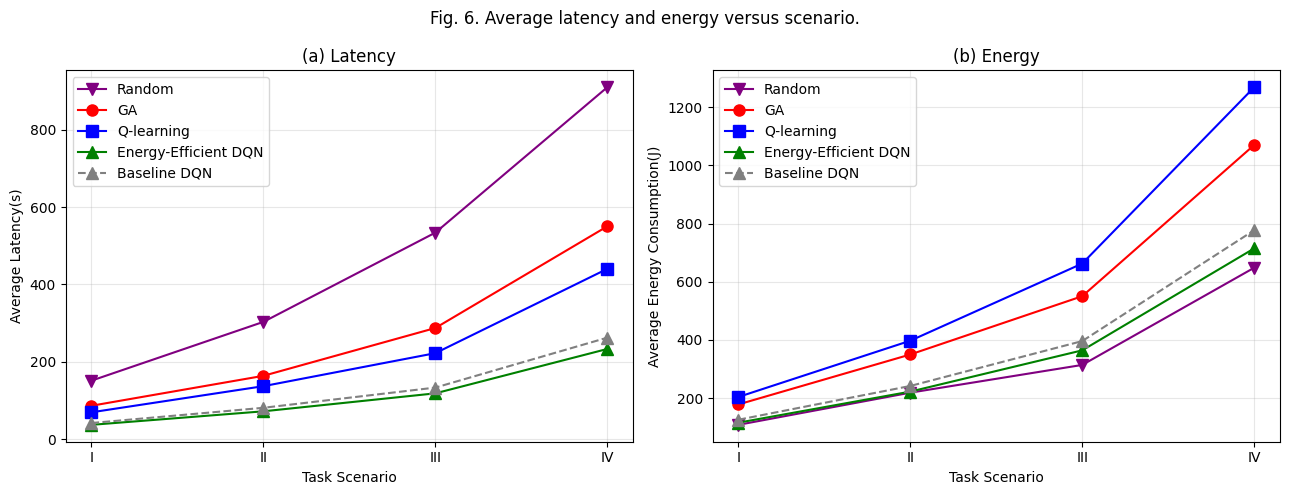

In [15]:
STYLE = {'Random': ('v-', 'purple'), 'GA': ('o-', 'red'), 'Q-learning': ('s-', 'blue'),
         'Energy-Efficient DQN': ('^-', 'green'), 'Baseline DQN': ('^--', 'gray')}

def plot_sweep(xs, res, xlabel, title, xticklabels=None):
    fig, axes = plt.subplots(1, 2, figsize=(13,5))
    for ax, i, ylab in [(axes[0], 0, 'Average Latency(s)'), (axes[1], 1, 'Average Energy Consumption(J)')]:
        for k, (m, c) in STYLE.items():
            ax.plot(xs, [v[i] for v in res[k]], m, color=c, label=k, ms=8)
        if xticklabels: ax.set_xticks(list(xs)); ax.set_xticklabels(xticklabels)
        ax.set_xlabel(xlabel); ax.set_ylabel(ylab); ax.legend(); ax.grid(alpha=0.3)
    axes[0].set_title('(a) Latency'); axes[1].set_title('(b) Energy')
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_sweep(range(len(scenarios)), res6, 'Task Scenario',
           'Fig. 6. Average latency and energy versus scenario.', scenarios)

## Fig. E: Partitioning Ratios of the Energy-Efficient DQN per Scenario

Scenario I: alpha=0.38, beta=0.31, gamma=0.31
Scenario II: alpha=0.38, beta=0.31, gamma=0.31
Scenario III: alpha=0.38, beta=0.31, gamma=0.31
Scenario IV: alpha=0.38, beta=0.31, gamma=0.31


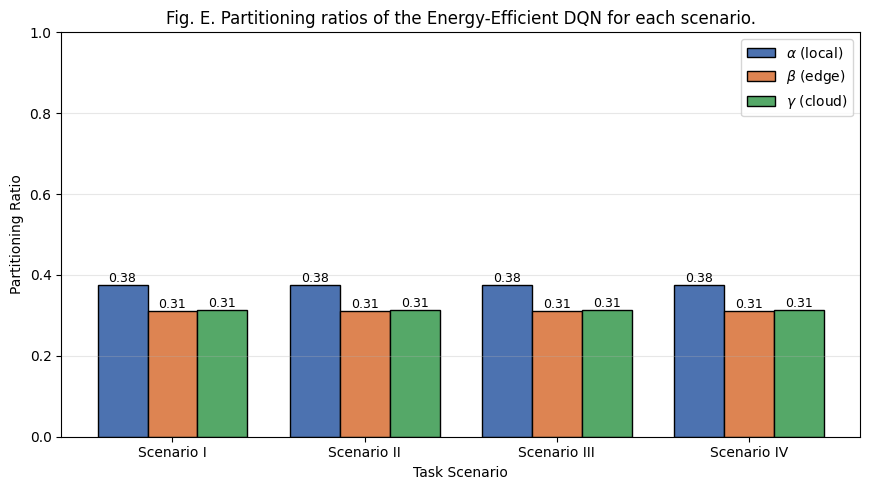

In [16]:
for sc, s in zip(scenarios, split6):
    print(f'Scenario {sc}: alpha={s[0]:.2f}, beta={s[1]:.2f}, gamma={s[2]:.2f}')
plot_splits([f'Scenario {sc}' for sc in scenarios], split6, 'Task Scenario',
            'Fig. E. Partitioning ratios of the Energy-Efficient DQN for each scenario.')

## Fig. 7: Average Latency and Energy vs. Density

In [17]:
print('Across densities...')
densities = [20, 25, 30, 35, 40, 45]
res7 = {k: [] for k in SCHEMES}

# Density affects EN load and the cloud share (more devices sharing compute)
for dens in densities:
    print(f'  {dens}...')
    sys_d = MECSystem('II')
    # Scale rates by density (more devices = more congestion = lower rates)
    sys_d.set_rate_scale(30.0 / dens)
    sys_d.en_load = np.maximum(1, (sys_d.en_load * dens / 30).astype(int))
    sys_d.n_cloud = N * dens / 30
    ag_d, _, _ = train_dqn(sys_d, n_epochs=100, steps_per_epoch=dens, verbose=False, ee=True)
    res7['Random'].append(eval_random(sys_d))
    res7['GA'].append(eval_ga(sys_d))
    res7['Q-learning'].append(eval_qlearning(sys_d))
    res7['Energy-Efficient DQN'].append(eval_dqn(ag_d, sys_d, ee=True))
    res7['Baseline DQN'].append(eval_dqn(None, sys_d))
    print('    ' + ', '.join(f'{k}={v[-1][0]:.1f}s/{v[-1][1]:.1f}J' for k, v in res7.items()))

Across densities...
  20...
    Random=243.3s/169.3J, GA=145.7s/318.8J, Q-learning=117.2s/292.2J, Energy-Efficient DQN=55.4s/139.3J, Baseline DQN=62.8s/182.4J
  25...
    Random=281.9s/200.3J, GA=157.5s/326.4J, Q-learning=126.6s/355.4J, Energy-Efficient DQN=64.7s/180.6J, Baseline DQN=72.8s/214.0J
  30...
    Random=286.1s/221.5J, GA=166.8s/335.0J, Q-learning=132.1s/392.0J, Energy-Efficient DQN=72.6s/222.1J, Baseline DQN=81.7s/241.5J
  35...
    Random=313.6s/229.5J, GA=187.7s/349.2J, Q-learning=152.4s/414.7J, Energy-Efficient DQN=78.9s/250.5J, Baseline DQN=88.2s/265.7J
  40...
    Random=352.4s/226.4J, GA=202.5s/378.3J, Q-learning=156.8s/430.4J, Energy-Efficient DQN=85.0s/280.5J, Baseline DQN=94.9s/284.4J
  45...
    Random=379.5s/246.5J, GA=222.8s/391.1J, Q-learning=152.1s/471.2J, Energy-Efficient DQN=90.4s/304.8J, Baseline DQN=100.8s/302.6J


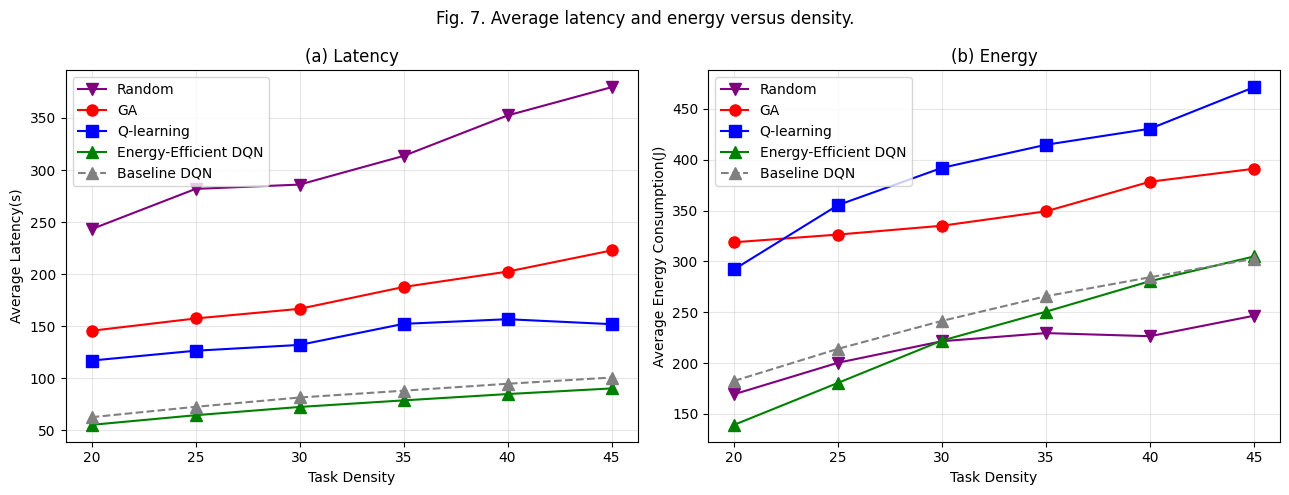

In [18]:
plot_sweep(densities, res7, 'Task Density', 'Fig. 7. Average latency and energy versus density.')

## Summary

**Model.** Objective $\sum_n (T_n + w_E E_n)$, with latency in s and energy in J. Decision variables: partition ratios
$\alpha_n, \beta_n, \gamma_n$ (0.05 grid), local CPU frequency $f^L \in$ {0.25, 0.5, 0.75, 1.0} GHz and transmit power
$P_n \in$ {0.25, 0.5, 0.75, 1.0} x 30 dBm. The cloud is shared: each device gets $c_n^C = C^C/N$.
Task sizes follow the realistic table at the top (20 KB to 1 GB).

**Baseline vs Energy-Efficient DQN (Figs. A, B).** The Energy-Efficient DQN lowers both latency and energy. Its power control
gives a faster uplink, so it moves work from the device to the edge and cloud (lower $\alpha$, higher $\beta$ and $\gamma$),
which is both faster and cheaper than local computation.

**All schemes (Figs. C, 6, 7).** Random, GA and Q-learning work under the energy-aware formulation with the same limits.
The ordering Energy-Efficient DQN < Baseline DQN < Q-learning < GA < Random holds on latency and on combined cost.
Every scheme is evaluated on the same fixed task set (equal counts per task type).

**Partitioning per scenario (Fig. E).** The ratios are the same in every scenario. Every latency and energy term is
proportional to the task size $d_n$, so the best fractions do not depend on how large the task is.
They depend only on the channel, the cycles per bit and the server loads.

**Concessions carried over from the latency-only notebook (see README):** DQN clean-channel rate, oracle DQN evaluation,
GA as a coarse random pick, density-based rate scaling, fixed inter-EN interference.
**Extension-specific:** Q-learning is averaged over 3 runs and uses a running-average update for its first visits;
DQN training uses a per-Mbit reward.